# Common distirbutions and the Central Limit Theorem

We will go over, very quickly, three common distributions - Binomial, Poisson, and Gaussian.



## The Binomial distribution

Number of successes in $n$ experiments with a pass or fail outcome.

PMF:

$$P(r; n, p) = p^r (1-p)^{n-r} {n \choose r} ,$$

where $P({ \rm pass}) = p$ and 

$${n \choose r} = \frac{n!}{r!(n-r)!} . $$



## The Poisson distribution 

Random variable $n$ is the number of events that occur when events occur independently and at a constant average rate $\lambda$.  Note, there is no number of experiments here.  

PMF:

$$P(n; \lambda) = \frac{e^{-\lambda} \lambda^n}{n!} ,$$

but be careful, as there is a difference between the rate $\lambda$ and the events per unit time $\tilde{\lambda}$.

### Poisson distribution example

It is common in astronomy to need to know how long to integrate for when observering a distant object.  Using what we know of a source, we can estimate how many photons per second should be arriving at the aperture of our telescope. What if we want to know how long to observe to have at least a 50% chance we get at least $M$ photons?

PMF:

$$P(n; \lambda) = \frac{e^{-\lambda} \lambda^n}{n!} ,$$

$$P(n \geq M; \lambda) = \sum_{n=M}^{\infty}\frac{e^{-\lambda} \lambda^n}{n!} ,$$

$$P(n \geq M; \lambda) = \sum_{n=M}^{\infty}\frac{e^{-(\tilde\lambda T)} (\tilde\lambda T)^n}{n!} ,$$

where $T$ is our integration time, and $\tilde\lambda$ is the number of photons arriving per second.

Now we could have a go at solving this analytically but I am a fan of numerical solutions.  So we need a few functions.  You also need a little bit of luck.  Rather than relying on luck, we have some tricks! 

#### Trick

Probability to the rescue!

$$P(n \geq M; \lambda) + P(n \lt M; \lambda) = 1 ,$$

$$P(n \lt M; \lambda) = \sum_{n=0}^{M-1}\frac{e^{-(\tilde\lambda T)} (\tilde\lambda T)^n}{n!} ,$$

$$P(n \geq M; \lambda) = 1 - P(n \lt M; \lambda) ,$$

$$P(n \geq M; \lambda) = 1 - \sum_{n=0}^{M-1}\frac{e^{-(\tilde\lambda T)} (\tilde\lambda T)^n}{n!} .$$

In [49]:
from math import factorial
import numpy as np

def PMF(tlambda: float, T: float, n: int) -> float: 
    return np.exp(-tlambda * T) * (tlambda * T)**n / factorial(n)

def sum_PMF(M: int, tlambda: float, T: float) -> float:
    return 1 - np.sum([PMF(tlambda, T, n) for n in range(M)])

tlambda = 3. # average counts per second expected
T = 1. # integration time 
for i in range(10):
    print(f' Chance of getting {i} or more counts, {sum_PMF(i, tlambda, T)}')

 Chance of getting 0 or more counts, 1.0
 Chance of getting 1 or more counts, 0.950212931632136
 Chance of getting 2 or more counts, 0.8008517265285442
 Chance of getting 3 or more counts, 0.5768099188731565
 Chance of getting 4 or more counts, 0.35276811121776874
 Chance of getting 5 or more counts, 0.18473675547622792
 Chance of getting 6 or more counts, 0.08391794203130343
 Chance of getting 7 or more counts, 0.033508535308841125
 Chance of getting 8 or more counts, 0.011904503856357329
 Chance of getting 9 or more counts, 0.0038029920616758917


## The Gaussian distribution

Note this is a continuous distribution.  I might also call this the normal distribution. 

PDF:

$$P(x; \mu, \sigma) = \frac{1}{\sqrt{2 \pi \sigma^2}} \exp \frac{-(x - \mu)^2}{2 \sigma^2} ,$$

where $-\infty \lt x \lt \infty$. 

There is a standard integral that will sometimes help you:

$$\int_{-\infty}^{\infty} {\rm d}x \exp \frac{-x^2}{2 \sigma^2} = \sqrt{2 \pi \sigma^2} .$$

Note, a more Bayesian notation and convientient way of writing this would be:

$$x \sim \mathcal{N} (\mu, \sigma^2) ,$$

which really means that we consider $x$ to be a random variable drawn from (or distributed according to) the normal distribution with the given mean and variance. 

### The MGF of the Gaussian Distribution

We learnt about MGF's so we may as well use them!

$$M_x(t) = \left< e^{tx} \right> = \int {\rm d}x \, P(x) \, e^{tx} ,$$

$$M_x(t) = \int {\rm d}x \, P(x; \mu, \sigma) \, e^{tx} ,$$

$$ = \int {\rm d}x \, \frac{1}{\sqrt{2 \pi \sigma^2}} \exp \frac{-(x - \mu)^2}{2 \sigma^2} \, e^{tx} ,$$

$$ =  \frac{1}{\sqrt{2 \pi \sigma^2}} \int {\rm d}x \, \exp \left( tx - \frac{(x - \mu)^2}{2 \sigma^2} \right),$$

For those of you who remember how to complete the square ... 

$$ =  \frac{1}{\sqrt{2 \pi \sigma^2}}  \exp \left( \mu t + \frac{\sigma^2t^2}{2} \right) \int {\rm d}x \, \exp \left(- \frac{(x - \mu - \sigma^2 t)^2}{2 \sigma^2} \right),$$

and now we rely on our standard integral:

$$\int_{-\infty}^{\infty} {\rm d}x \exp \frac{-x^2}{2} = \sqrt{2 \pi} ,$$

but first we make the following substitution:

$$u = (x - \mu - \sigma^2 t)$$

$$\int_{-\infty}^{\infty} {\rm d}x \exp \frac{-u^2}{2 \sigma^2} = \sqrt{2 \pi \sigma^2} .$$

Amazlingly, this gives, 

$$M_x(t) = \exp \left( \mu t + \frac{\sigma^2t^2}{2} \right) $$

### The moments of the Normal distribution

What do we do with MGF's?  We calculate the non-central moments.

$$ \mu_k = \frac{{\rm d}^k}{{\rm d}t^k} \bigg\rvert _{t=0} \, M_x(t) .$$

#### Finding the mean:

$$\left< x \right> = \mu_1 = \frac{{\rm d}}{{\rm d}t} \bigg\rvert _{t=0} \, M_x(t) ,$$

Using the chain rule, 

$$\left< x \right> = (\mu + \sigma^2 t) \, M_x(t) \,  \bigg\rvert _{t=0} ,$$

and the simplifying

$$\left< x \right> = \mu .$$

#### Finding the variance:

From our earlier definition,

$${\rm Var}(x) = \left< x^2 \right> - \left< x\right>^2 = \mu_2 - \mu_1^2,$$ 

we have, 

$$ \mu_2 = \frac{{\rm d}^2}{{\rm d}t^2} \bigg\rvert _{t=0} \, M_x(t) ,$$

$$ \mu_2 = \frac{{\rm d}}{{\rm d}t} \bigg\rvert _{t=0} \, (\mu + \sigma^2 t) \, M_x(t) ,$$

$$ = \left[ \sigma^2 M_x(t) + (\mu + \sigma^2 t)^2 \, M_x(t) \right] \bigg\rvert _{t=0} ,$$

$$ = \sigma^2 + \mu^2 .$$

So, 

$${\rm Var}(x) = \left< x^2 \right> - \left< x\right>^2 = \mu_2 - \mu_1^2,$$ 

$$ {\rm Var}(x) = \mu_2 - \mu_1^2 = \sigma^2 + \mu^2 - \mu^2 =  \sigma^2 , $$

$$ {\rm Var}(x) =  \sigma^2 . $$

Which is sort of neat that we can show this, but you knew all this anyway.

## Multivariate distributions

Multi-variate continuous distributions!

Let $x$ and $y$ be continuous random variables.  We can have a 2D PDF:

$$P(x, y) , $$

and we can work out the probability of some result:

$${\rm Prob}(a \leq x \leq b, \, c \leq y \leq d) = \int_a^b \int_c^d P(x, y) \, {\rm d}x \,  {\rm d}y .$$

If $x$ and $y$ are independent then the PDF is seperable,

$$P(x, y) = P(x) \, P(y) .$$

#### 1D marginal distribution

We marginalise (integrate) over the nusiance variable,

$$P(x) = \int {\rm d}y \, P(x, y) .$$

#### 1D conditional distribution

For example, what if we want to know the PDF of $x$ for when $y=Y$, i.e., the conditional distribution,

$$P(x| y=Y) = P(x, y=Y) ,$$

noting that this will not be normalised. And so, 

$$P(x| y=Y) = \frac{P(x, y=Y)}{\int {\rm d}x' P(x', y=Y)} .$$


In [8]:
import numpy as np
import seaborn as sns

penguins = sns.load_dataset("penguins")
penguins = penguins.sample(frac=1)
penguins.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
307,Gentoo,Biscoe,51.3,14.2,218.0,5300.0,Male
26,Adelie,Biscoe,40.6,18.6,183.0,3550.0,Male
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
69,Adelie,Torgersen,41.8,19.4,198.0,4450.0,Male
19,Adelie,Torgersen,46.0,21.5,194.0,4200.0,Male


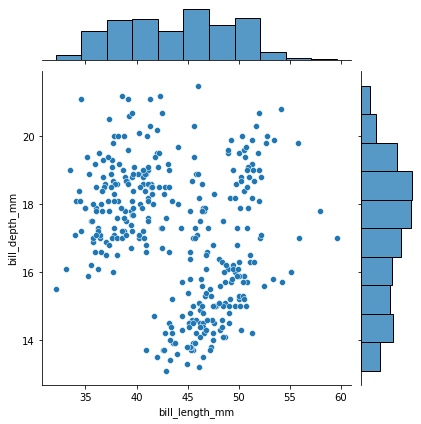

In [6]:
sns.jointplot(data=penguins, x="bill_length_mm", y="bill_depth_mm")

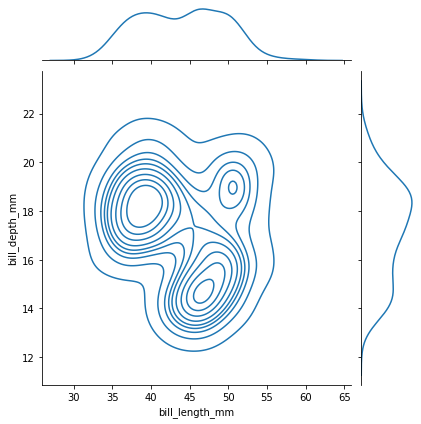

In [4]:
sns.jointplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", kind='kde')

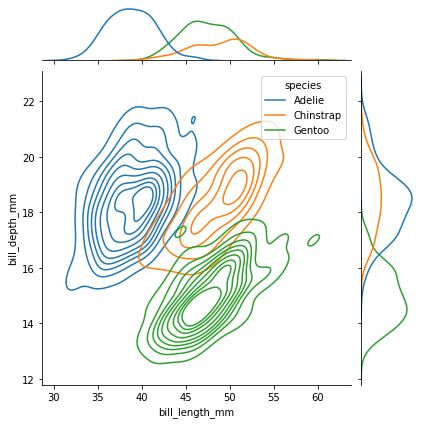

In [3]:
sns.jointplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", hue="species", kind="kde")

Other small points:

$$\left< f(x, y) \right> = \int {\rm d}x \int {\rm d}y \, f(x, y) \, P(x, y) ,$$

$${\rm Var}(x) = \left< (x - \left< x \right>)^2 \right> = \int {\rm d}x \int {\rm d}y \, (x - \left< x \right>)^2 \, P(x, y) ,$$

where, 

$$ \left< x \right> = \int {\rm d}x \int {\rm d}y \, x \, P(x, y) .$$

### Covariance 

Covariance can be defined:

$${\rm Cov}(x, y) = \left<(x - \left< x \right>)(y - \left< y \right>) \right> , $$

and Correlation:

$${\rm Corr}(x, y) = \frac{{\rm Cov}(x, y)}{\sigma_x \, \sigma_y}$$